In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import polars.selectors as cs
import math
import seaborn as sns

In [2]:
df = pl.read_csv('../data/ofiq_glint_10000.csv', 
                 separator=';',
                infer_schema_length=10000
                ).drop(['Filename','assessment_time_in_ms', ''])
df.head(5)

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native,UnifiedQualityScore.scalar,BackgroundUniformity.scalar,IlluminationUniformity.scalar,LuminanceMean.scalar,LuminanceVariance.scalar,UnderExposurePrevention.scalar,OverExposurePrevention.scalar,DynamicRange.scalar,Sharpness.scalar,NoCompressionArtifacts.scalar,NaturalColour.scalar,SingleFacePresent.scalar,EyesOpen.scalar,MouthClosed.scalar,EyesVisible.scalar,MouthOcclusionPrevention.scalar,FaceOcclusionPrevention.scalar,InterEyeDistance.scalar,HeadSize.scalar,LeftwardCropOfFace.scalar,RightwardCropOfFace.scalar,MarginAboveTheFace.scalar,MarginBelowTheFace.scalar,HeadPoseYawFrontal.scalar,HeadPosePitchFrontal.scalar,HeadPoseRollFrontal.scalar,ExpressionNeutrality.scalar,NoHeadCoverings.scalar
f64,f64,f64,f64,f64,str,str,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64
17.738901,9.68865,0.477539,0.343636,0.016415,"""0.035459""","""0""",6.777683,13,0.937676,0.0,0.0,0.064197,0.02226,0.0,0.0,0.047893,34.019953,0.567245,2.146131,2.146131,0.840846,0.936036,1.006597,-0.897973,0.865835,8237.666016,0.222589,12,95,80,95,100,100,100,85,90,100,100,100,99,95,100,100,95,14,17,100,100,0,0,100,100,100,93,21
17.751863,70.244927,0.33642,0.21658,0.007379,"""0.069950""","""0""",6.382081,-14,0.878365,0.0,0.0,0.069849,0.152186,0.0,0.0,0.160796,39.319568,0.531269,1.922445,1.948078,0.949016,0.949016,-7.161569,-1.141383,-0.587368,-12527.116211,0.063622,12,67,72,58,82,100,100,80,55,100,100,100,99,69,100,100,84,18,33,100,100,1,0,98,100,100,18,71
19.499258,31.436392,0.235102,0.081811,0.00494,"""0.620473""","""0""",5.613438,37,0.88605,0.0,0.0,0.083779,0.016748,0.0,0.0,0.114281,36.454804,0.533122,2.08253,2.026996,0.911985,0.97954,-8.920267,5.328603,-1.156726,1310.250977,0.0,21,85,65,9,66,100,100,70,98,100,100,100,100,95,100,100,89,16,32,100,100,1,0,98,99,100,78,100
20.089495,156.120505,0.742857,0.410544,0.017607,"""0.037574""","""0""",6.962691,30,0.88891,0.0,0.0,0.046875,0.016657,0.0,0.0,0.094491,37.552252,0.536012,2.080126,2.024656,0.866186,0.999445,-16.23102,24.47632,4.456272,-5505.63623,0.201543,25,36,91,98,100,100,100,87,97,100,100,100,94,96,100,100,91,16,30,100,100,0,0,92,83,99,47,25
24.019133,8.705271,0.358726,0.305254,0.037769,"""0.132049""","""0""",7.178152,50,0.932934,100.0,0.0,0.034653,0.144882,0.0,0.0,0.141193,39.332402,0.558054,1.948078,1.922445,0.886981,0.919235,-7.308852,-8.89553,-0.460576,-13936.230469,0.0,60,96,74,89,82,100,100,90,100,100,0,100,81,71,100,100,86,18,21,100,100,1,0,98,98,100,14,100


In [3]:
df.select(pl.col(pl.Float32,pl.Float64).is_nan().sum())

UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,DynamicRange.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [4]:
# Togliere le entry con NaN
df = df.filter(
    ~pl.any_horizontal(pl.col(pl.Float32, pl.Float64).is_nan())\
)

In [5]:
native = df.select(cs.ends_with('.native'))
scalar = df.select(cs.ends_with('.scalar'))
print(scalar.shape)
print(native.shape)
scalar.columns

(5000, 28)
(5000, 28)


['UnifiedQualityScore.scalar',
 'BackgroundUniformity.scalar',
 'IlluminationUniformity.scalar',
 'LuminanceMean.scalar',
 'LuminanceVariance.scalar',
 'UnderExposurePrevention.scalar',
 'OverExposurePrevention.scalar',
 'DynamicRange.scalar',
 'Sharpness.scalar',
 'NoCompressionArtifacts.scalar',
 'NaturalColour.scalar',
 'SingleFacePresent.scalar',
 'EyesOpen.scalar',
 'MouthClosed.scalar',
 'EyesVisible.scalar',
 'MouthOcclusionPrevention.scalar',
 'FaceOcclusionPrevention.scalar',
 'InterEyeDistance.scalar',
 'HeadSize.scalar',
 'LeftwardCropOfFace.scalar',
 'RightwardCropOfFace.scalar',
 'MarginAboveTheFace.scalar',
 'MarginBelowTheFace.scalar',
 'HeadPoseYawFrontal.scalar',
 'HeadPosePitchFrontal.scalar',
 'HeadPoseRollFrontal.scalar',
 'ExpressionNeutrality.scalar',
 'NoHeadCoverings.scalar']

#### Data distribution

In [6]:
def create_histograms(df, n_cols=4, bins=40, clip=(1, 99), drop_errors=True):
    n_rows = math.ceil(df.shape[1] / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.5 * n_rows))
    axes = np.array(axes).flatten()

    for ax, name in zip(axes, df.columns):
        values = df[name].drop_nulls().to_numpy().astype(float)
        values = values[~np.isnan(values)]
        if drop_errors:
            values = values[values != -1]          
        if len(values) == 0:
            ax.set_title(f"{name} (vuota)")
            continue
        lo, hi = np.percentile(values, clip)
        if lo == hi:                              
            lo, hi = values.min(), values.max() + 1e-9
        ax.hist(values, bins=bins, range=(lo, hi), edgecolor="white", linewidth=0.4)
        ax.set_title(name, fontsize=9)

    for ax in axes[len(df.columns):]:
        ax.set_visible(False)                

    fig.tight_layout()
    return fig

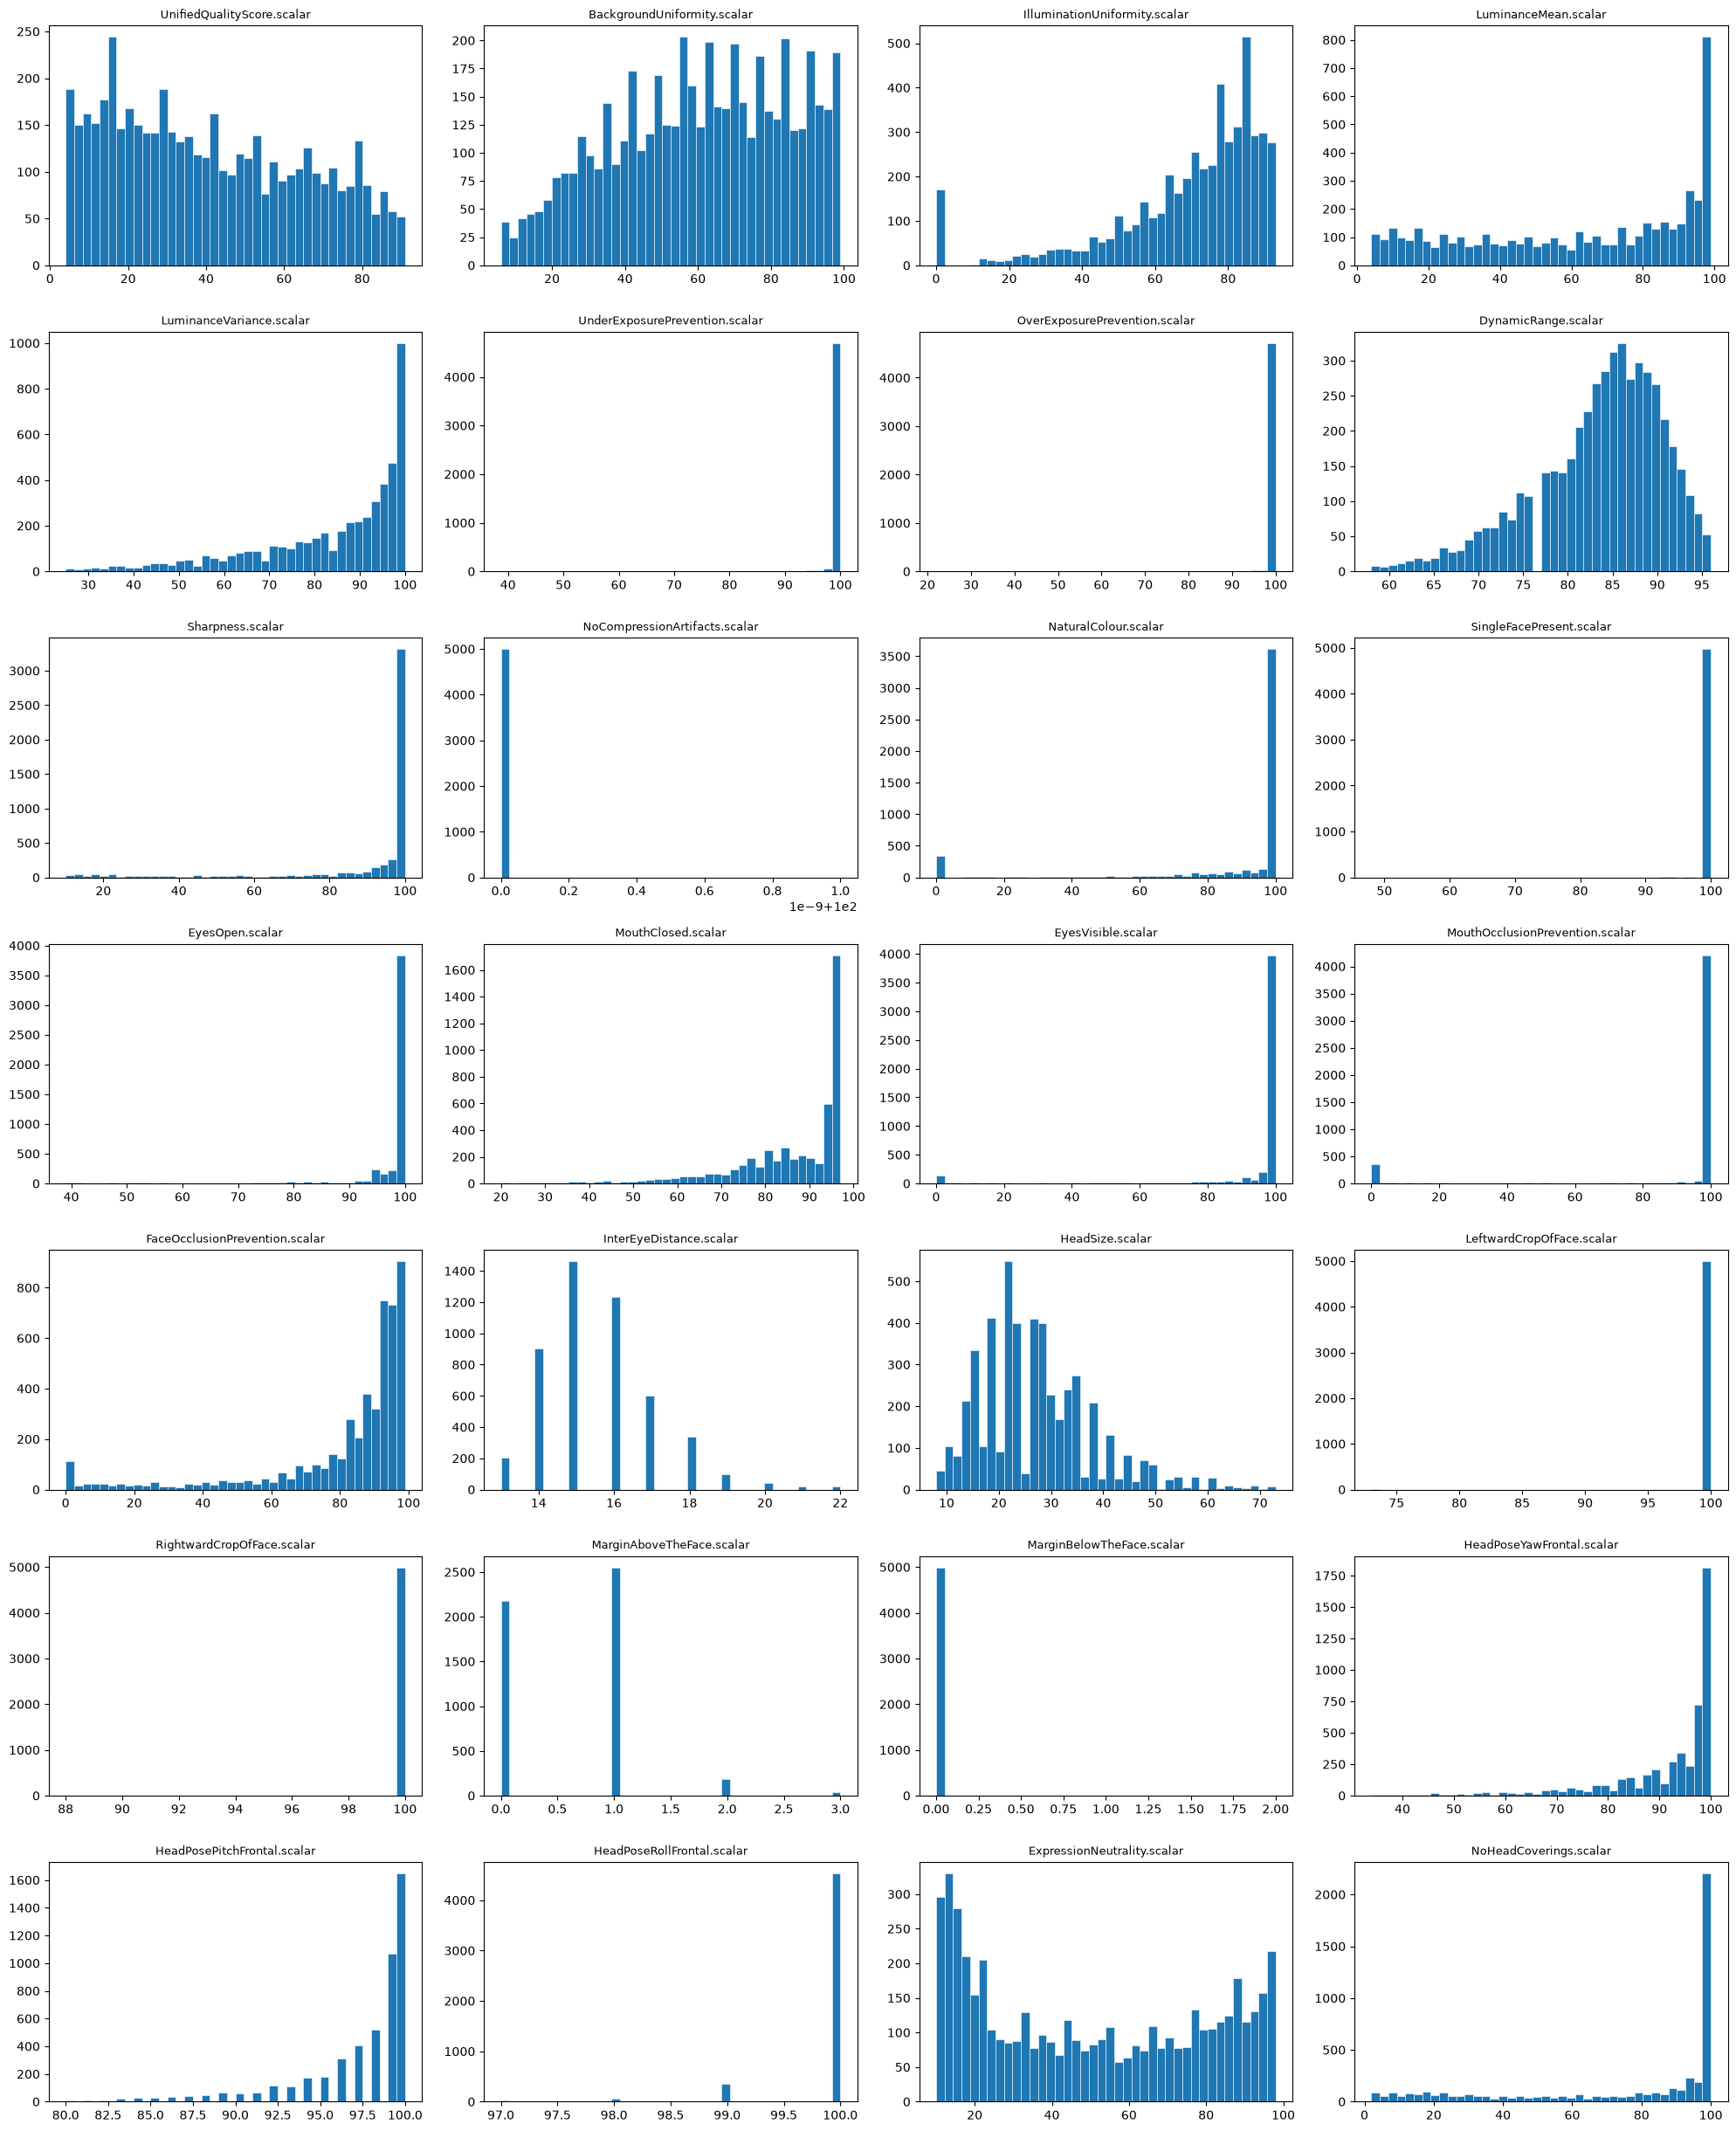

In [7]:
create_histograms(scalar);

There are columns that cannot be studied because they reach saturation.

Most of these histograms show repetitive pattern, peak at the max value with a skew on the left, with only few exception with peak at the minimum value but often followed with another peak with less height.

This shows that a dataset with 200 images can't put a good distribution for each one of the features, it can be solved by adding more inputs or without using scalar values and go straight to the .native values.

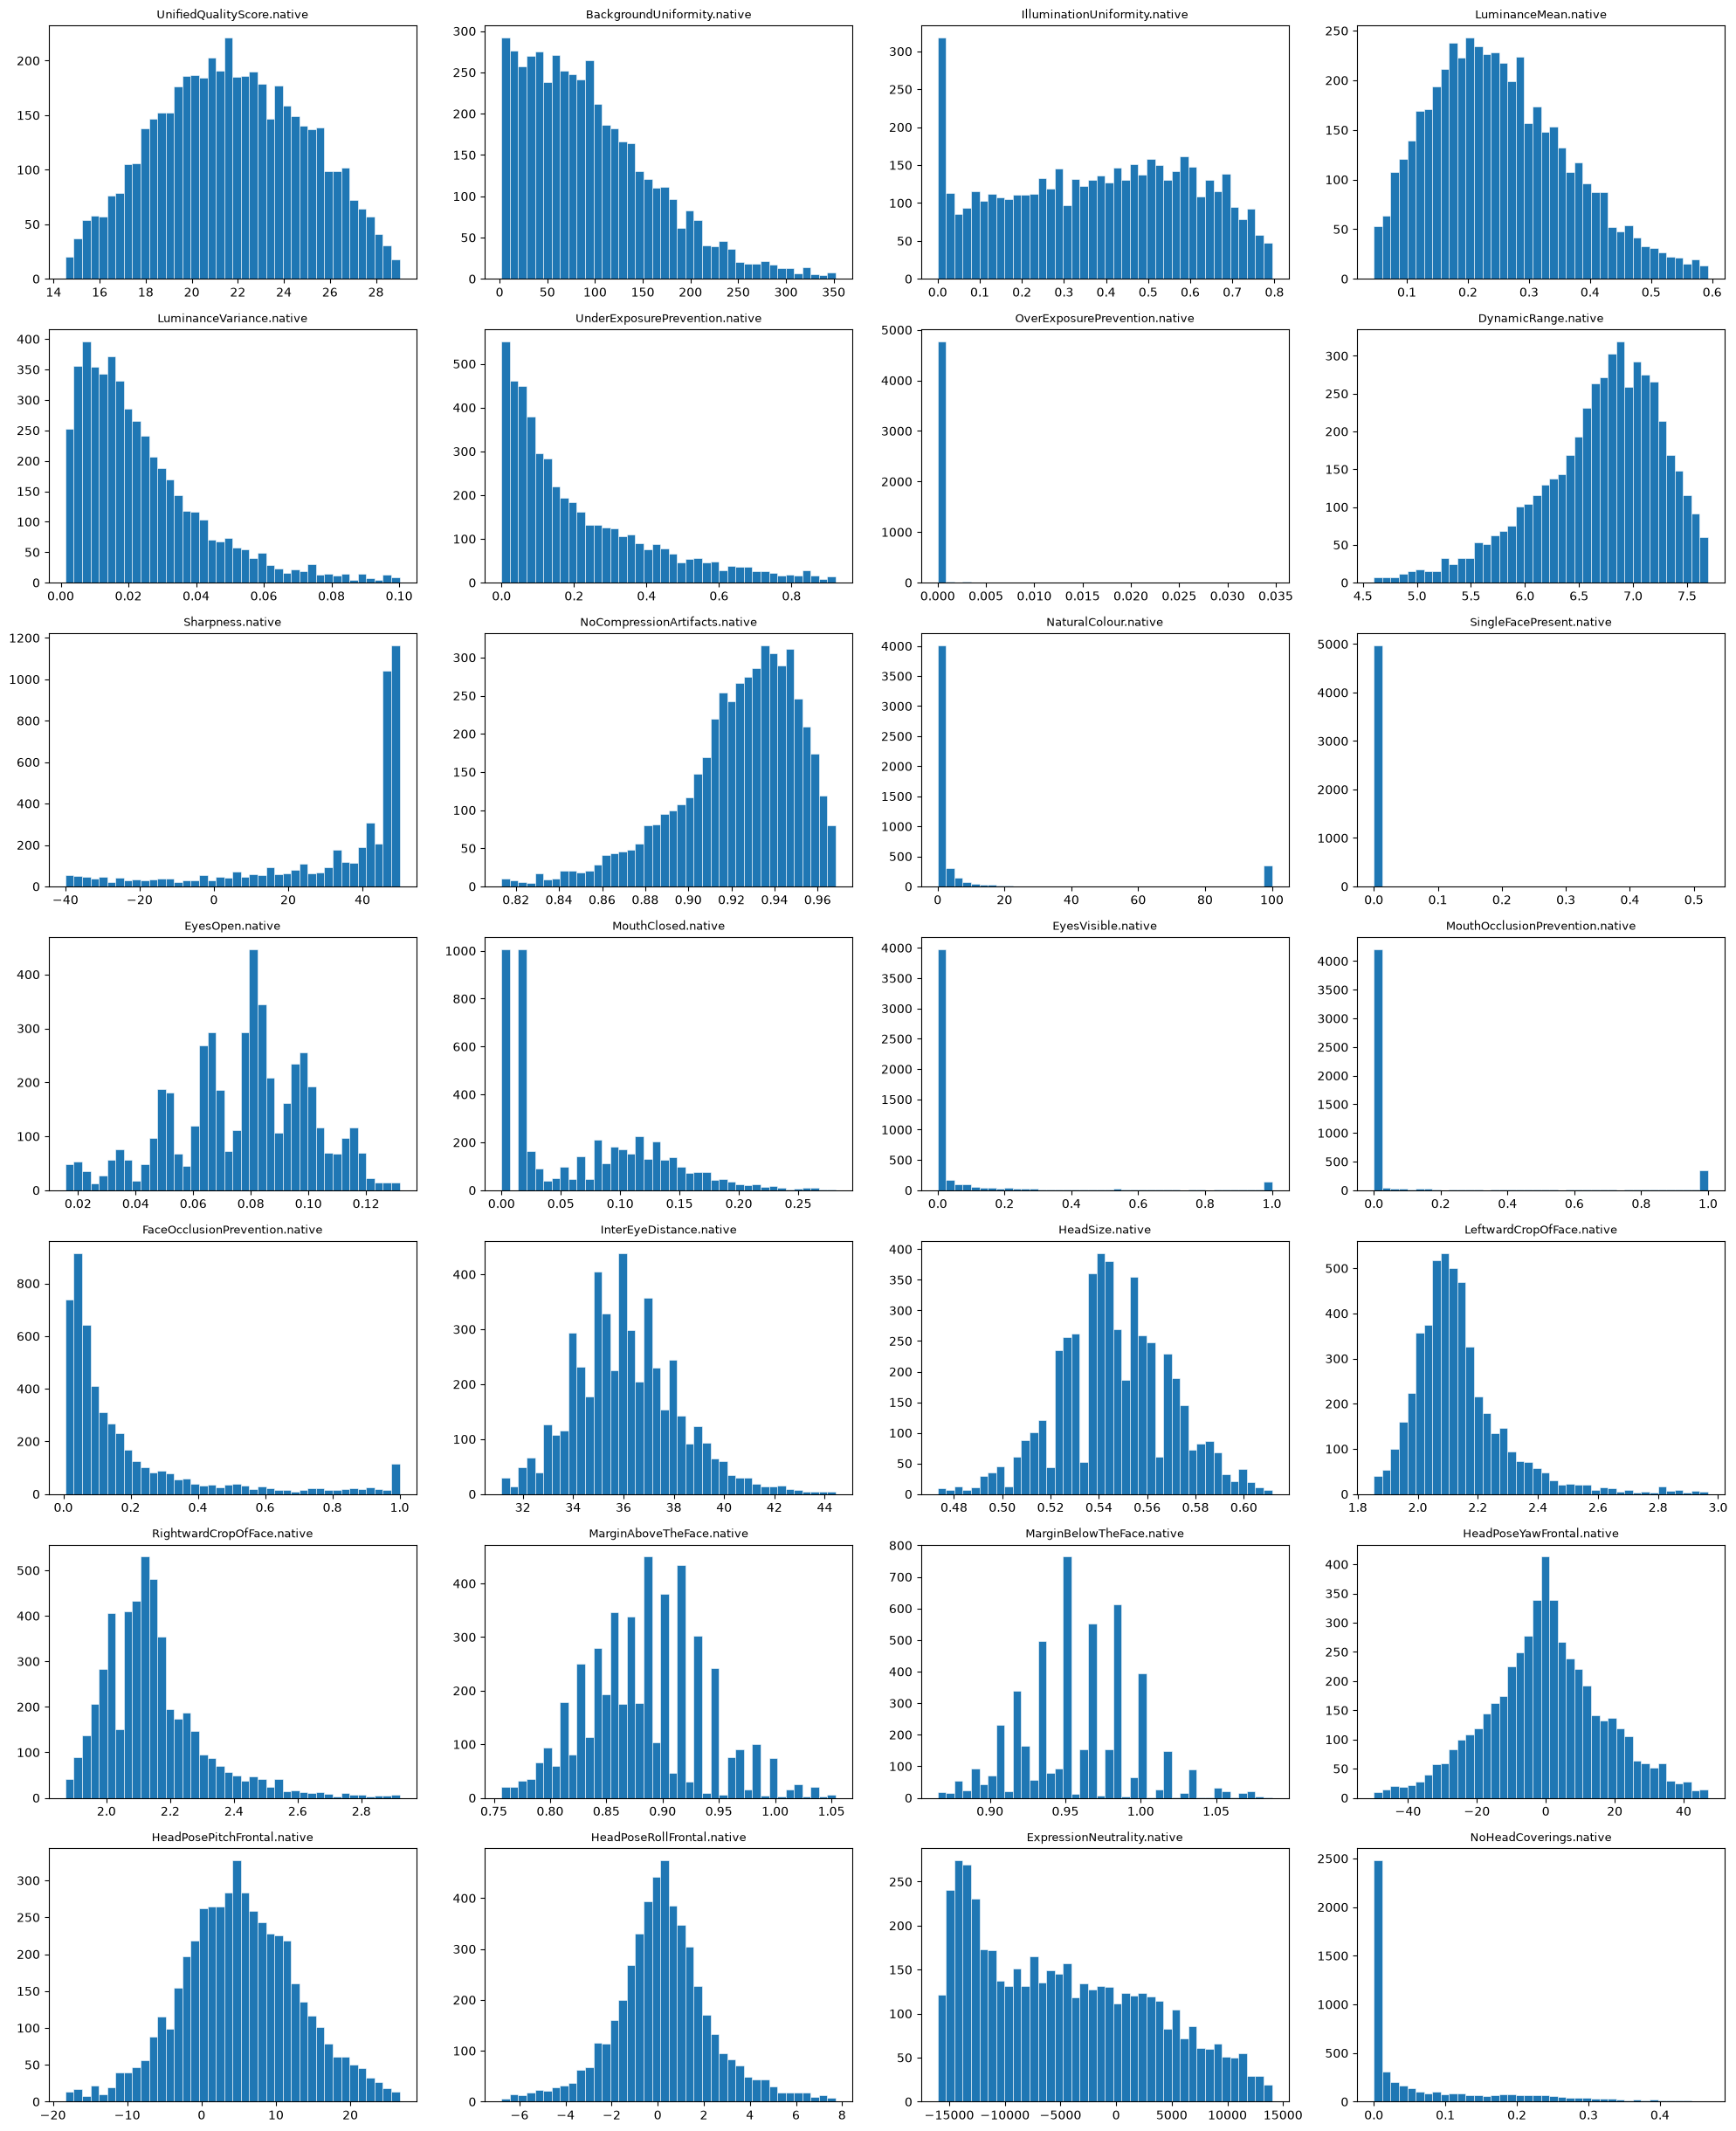

In [8]:
create_histograms(native);

With the .native DataFrame we cen see different type if distribution in comparison of the .scalar dataframe. 
9 out of the 28 columns shows peak near the min value of the feature with a right skew, but rather it is optimal for the other features that have much stronger distribution of datas.

We will continue the data exploration with the .native.

#### Mean and Variabilty of the data

In [9]:
df_describe = native.describe()
mean = df_describe.filter(pl.col('statistic') == 'mean')
median = df_describe.filter(pl.col('statistic') == '50%')

In [10]:
df_describe

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",5000.0,5000.0,5000.0,5000.0,5000.0,"""5000""","""5000""",5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0,5000.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,"""0""","""0""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",21.699567,97.988516,0.384156,0.255651,0.024605,null,null,6.667632,30.2372,0.921387,7.965563,0.00074,0.077036,0.071826,0.072794,0.105899,0.18346,36.224014,0.546002,2.142651,2.152795,0.882932,0.957259,-0.199684,5.179777,0.214349,-4651.9604,0.074655
"""std""",3.421976,76.625015,0.226113,0.121373,0.02071,null,null,0.657628,25.06318,0.040927,25.283396,0.014598,0.025019,0.068925,0.212022,0.286036,0.232194,3.335008,0.030172,0.210685,0.210666,0.064435,0.05089,18.577415,8.670187,2.692798,8047.801598,0.113285
"""min""",0.0,0.0,0.0,0.0,0.0,"""0""","""0""",0.0,-46.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-74.949714,-35.202454,-46.807667,-17972.773438,0.0
"""25%""",19.283924,40.513521,0.195763,0.166951,0.010231,null,null,6.346992,20.0,0.907701,0.0,0.0,0.062947,0.015999,0.0,0.0,0.042787,34.700377,0.531325,2.027744,2.05106,0.843647,0.933298,-10.625789,-0.055206,-0.94357,-11979.613281,0.0
"""50%""",21.631893,83.302879,0.396684,0.24076,0.01896,null,null,6.783371,43.0,0.927918,0.0,0.0,0.0801,0.062483,0.0,0.0,0.088557,36.037191,0.5451,2.113423,2.114286,0.882843,0.951613,-0.247041,4.954946,0.196089,-5675.391113,0.012156
"""75%""",24.192345,136.969953,0.573003,0.328825,0.032649,null,null,7.115102,47.0,0.944272,1.108573,0.0,0.095065,0.119741,0.007708,0.0,0.208831,37.391051,0.562571,2.202076,2.211106,0.916158,0.982787,10.370757,10.482571,1.378919,1493.90979,0.116671
"""max""",31.810921,955.29661,0.875102,0.893664,0.179619,"""nan""","""nan""",7.883521,50.0,0.97936,100.0,0.522114,0.202403,0.474665,1.0,1.0,1.0,152.225076,0.844258,4.445299,4.532899,1.453911,1.402897,84.25741,52.598942,21.672936,18554.873047,0.692972


In [11]:
mean

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""mean""",21.699567,97.988516,0.384156,0.255651,0.024605,null,null,6.667632,30.2372,0.921387,7.965563,0.00074,0.077036,0.071826,0.072794,0.105899,0.18346,36.224014,0.546002,2.142651,2.152795,0.882932,0.957259,-0.199684,5.179777,0.214349,-4651.9604,0.074655


In [12]:
median

statistic,UnifiedQualityScore.native,BackgroundUniformity.native,IlluminationUniformity.native,LuminanceMean.native,LuminanceVariance.native,UnderExposurePrevention.native,OverExposurePrevention.native,DynamicRange.native,Sharpness.native,NoCompressionArtifacts.native,NaturalColour.native,SingleFacePresent.native,EyesOpen.native,MouthClosed.native,EyesVisible.native,MouthOcclusionPrevention.native,FaceOcclusionPrevention.native,InterEyeDistance.native,HeadSize.native,LeftwardCropOfFace.native,RightwardCropOfFace.native,MarginAboveTheFace.native,MarginBelowTheFace.native,HeadPoseYawFrontal.native,HeadPosePitchFrontal.native,HeadPoseRollFrontal.native,ExpressionNeutrality.native,NoHeadCoverings.native
str,f64,f64,f64,f64,f64,str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""50%""",21.631893,83.302879,0.396684,0.24076,0.01896,null,null,6.783371,43.0,0.927918,0.0,0.0,0.0801,0.062483,0.0,0.0,0.088557,36.037191,0.5451,2.113423,2.114286,0.882843,0.951613,-0.247041,4.954946,0.196089,-5675.391113,0.012156


In [13]:
for c1, c2 in zip(mean.columns, median.columns):
    print(f"Column {c1}")
    print(f"Mean: {mean[c1].to_numpy().item()}")
    print(f"Median: {median[c1].to_numpy().item()}")
    print("==============")

Column statistic
Mean: mean
Median: 50%
Column UnifiedQualityScore.native
Mean: 21.6995669304
Median: 21.631893
Column BackgroundUniformity.native
Mean: 97.9885158834
Median: 83.302879
Column IlluminationUniformity.native
Mean: 0.38415645440000007
Median: 0.396684
Column LuminanceMean.native
Mean: 0.25565061800000005
Median: 0.24076
Column LuminanceVariance.native
Mean: 0.024604775600000003
Median: 0.01896
Column UnderExposurePrevention.native
Mean: None
Median: None
Column OverExposurePrevention.native
Mean: None
Median: None
Column DynamicRange.native
Mean: 6.667632257199999
Median: 6.783371
Column Sharpness.native
Mean: 30.2372
Median: 43.0
Column NoCompressionArtifacts.native
Mean: 0.9213865461999998
Median: 0.927918
Column NaturalColour.native
Mean: 7.965563190800001
Median: 0.0
Column SingleFacePresent.native
Mean: 0.0007396086
Median: 0.0
Column EyesOpen.native
Mean: 0.07703632560000001
Median: 0.0801
Column MouthClosed.native
Mean: 0.07182601220000001
Median: 0.062483
Column Ey

In [14]:
distance = df_describe.select(
    cs.numeric().filter(pl.col("statistic") == "max").first()
    - cs.numeric().filter(pl.col("statistic") == "min").first()
)

for col in distance.columns:
    print(col)
    print(f"Distanza: {distance[col].to_numpy().item()}")
    print("============")

UnifiedQualityScore.native
Distanza: 31.810921
BackgroundUniformity.native
Distanza: 955.29661
IlluminationUniformity.native
Distanza: 0.875102
LuminanceMean.native
Distanza: 0.893664
LuminanceVariance.native
Distanza: 0.179619
DynamicRange.native
Distanza: 7.883521
Sharpness.native
Distanza: 96.0
NoCompressionArtifacts.native
Distanza: 0.97936
NaturalColour.native
Distanza: 100.0
SingleFacePresent.native
Distanza: 0.522114
EyesOpen.native
Distanza: 0.202403
MouthClosed.native
Distanza: 0.474665
EyesVisible.native
Distanza: 1.0
MouthOcclusionPrevention.native
Distanza: 1.0
FaceOcclusionPrevention.native
Distanza: 1.0
InterEyeDistance.native
Distanza: 152.225076
HeadSize.native
Distanza: 0.844258
LeftwardCropOfFace.native
Distanza: 4.445299
RightwardCropOfFace.native
Distanza: 4.532899
MarginAboveTheFace.native
Distanza: 1.453911
MarginBelowTheFace.native
Distanza: 1.402897
HeadPoseYawFrontal.native
Distanza: 159.207124
HeadPosePitchFrontal.native
Distanza: 87.80139600000001
HeadPoseRol

In [15]:
std = df_describe.filter(pl.col('statistic') == 'std')

for col in std.columns:
    print(col)
    print(f"Varianza: {std[col].to_numpy().item()}")
    print("========================")

statistic
Varianza: std
UnifiedQualityScore.native
Varianza: 3.421975616271169
BackgroundUniformity.native
Varianza: 76.62501476069157
IlluminationUniformity.native
Varianza: 0.2261130900837803
LuminanceMean.native
Varianza: 0.1213725771198281
LuminanceVariance.native
Varianza: 0.020710007059509313
UnderExposurePrevention.native
Varianza: None
OverExposurePrevention.native
Varianza: None
DynamicRange.native
Varianza: 0.6576281528605529
Sharpness.native
Varianza: 25.063179541984507
NoCompressionArtifacts.native
Varianza: 0.04092730944923224
NaturalColour.native
Varianza: 25.283396395765692
SingleFacePresent.native
Varianza: 0.014597639449352922
EyesOpen.native
Varianza: 0.025018858016657684
MouthClosed.native
Varianza: 0.06892454845756821
EyesVisible.native
Varianza: 0.21202211199625148
MouthOcclusionPrevention.native
Varianza: 0.28603556368560035
FaceOcclusionPrevention.native
Varianza: 0.2321936612950714
InterEyeDistance.native
Varianza: 3.3350077265102023
HeadSize.native
Varianza: 0.

Big range of datas:
- Sharpness.native --> Distance: 89.0
- BackgroundUniformity.native --> Distance: 394.722418
- ExpressionNeutrality.native --> Distance: 33017.516602

Variance:
- ExpressionNeutrality.native --> Variance: 8572.953698773426
- BackgroundUniformity.native --> Variance: 74.51952757612418
- NaturalColour.native --> Variance: 27.161944465058568

##### Percentili

In [33]:
def whisker_and_box_diagram(df):
    col = 4

    numeric_columns = [
        name for name in df.columns
        if df[name].dtype.is_numeric()
    ]
    row = math.ceil(len(numeric_columns) / col)
    fig, ax = plt.subplots(row, col, figsize=(20, 4 * row))
    ax = np.array(ax).flatten()

    for i, name in enumerate(numeric_columns):
        column = df[name].drop_nulls().to_numpy()

        if len(column) == 0:
            continue

        q1 = np.percentile(column, 25)
        med = np.percentile(column, 50)
        q3 = np.percentile(column, 75)

        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr

        fliers = column[
            (column < lower_limit) | (column > upper_limit)
        ]

        whislo = np.min(column[column >= lower_limit])
        whishi = np.max(column[column <= upper_limit])

        plt_data = [{
            'label': "",
            'whislo': whislo,
            'q1': q1,
            'med': med,
            'q3': q3,
            'whishi': whishi,
            'fliers': fliers
        }]

        ax[i].bxp(plt_data, orientation="horizontal")
        ax[i].set_title(name)
    for i in range(len(numeric_columns), len(ax)):
        fig.delaxes(ax[i])
    plt.show()

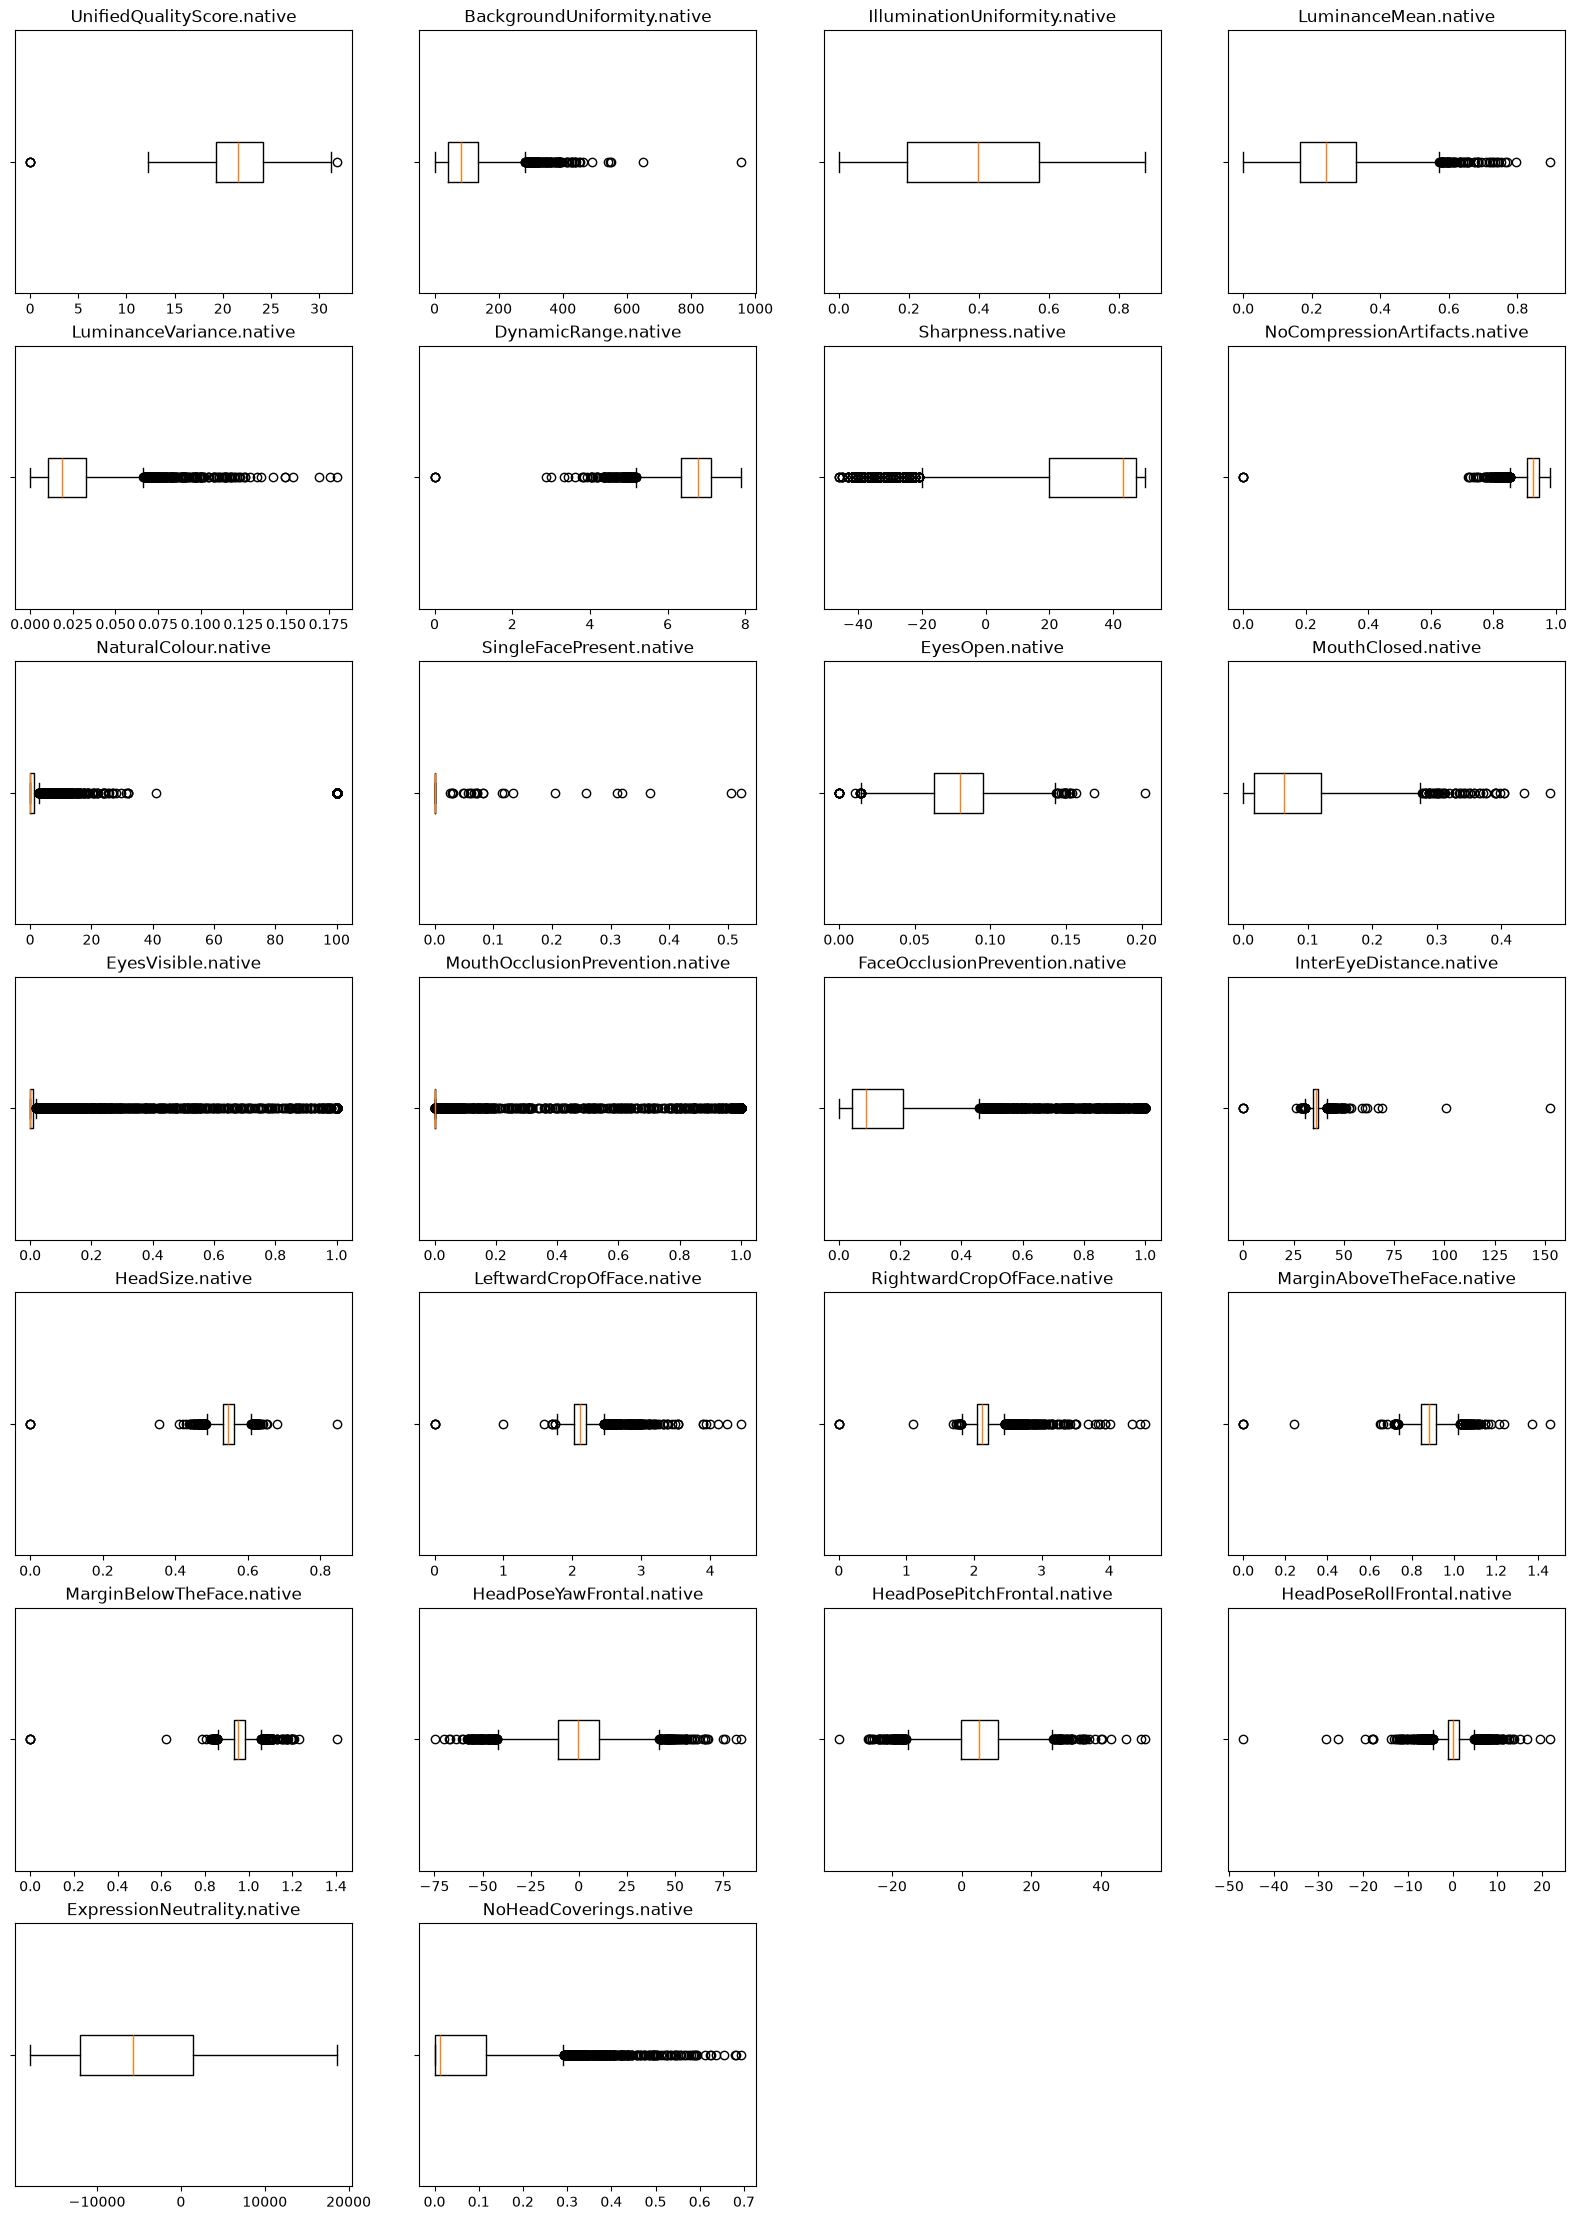

In [34]:
whisker_and_box_diagram(native)

#### Eventuali correlazioni

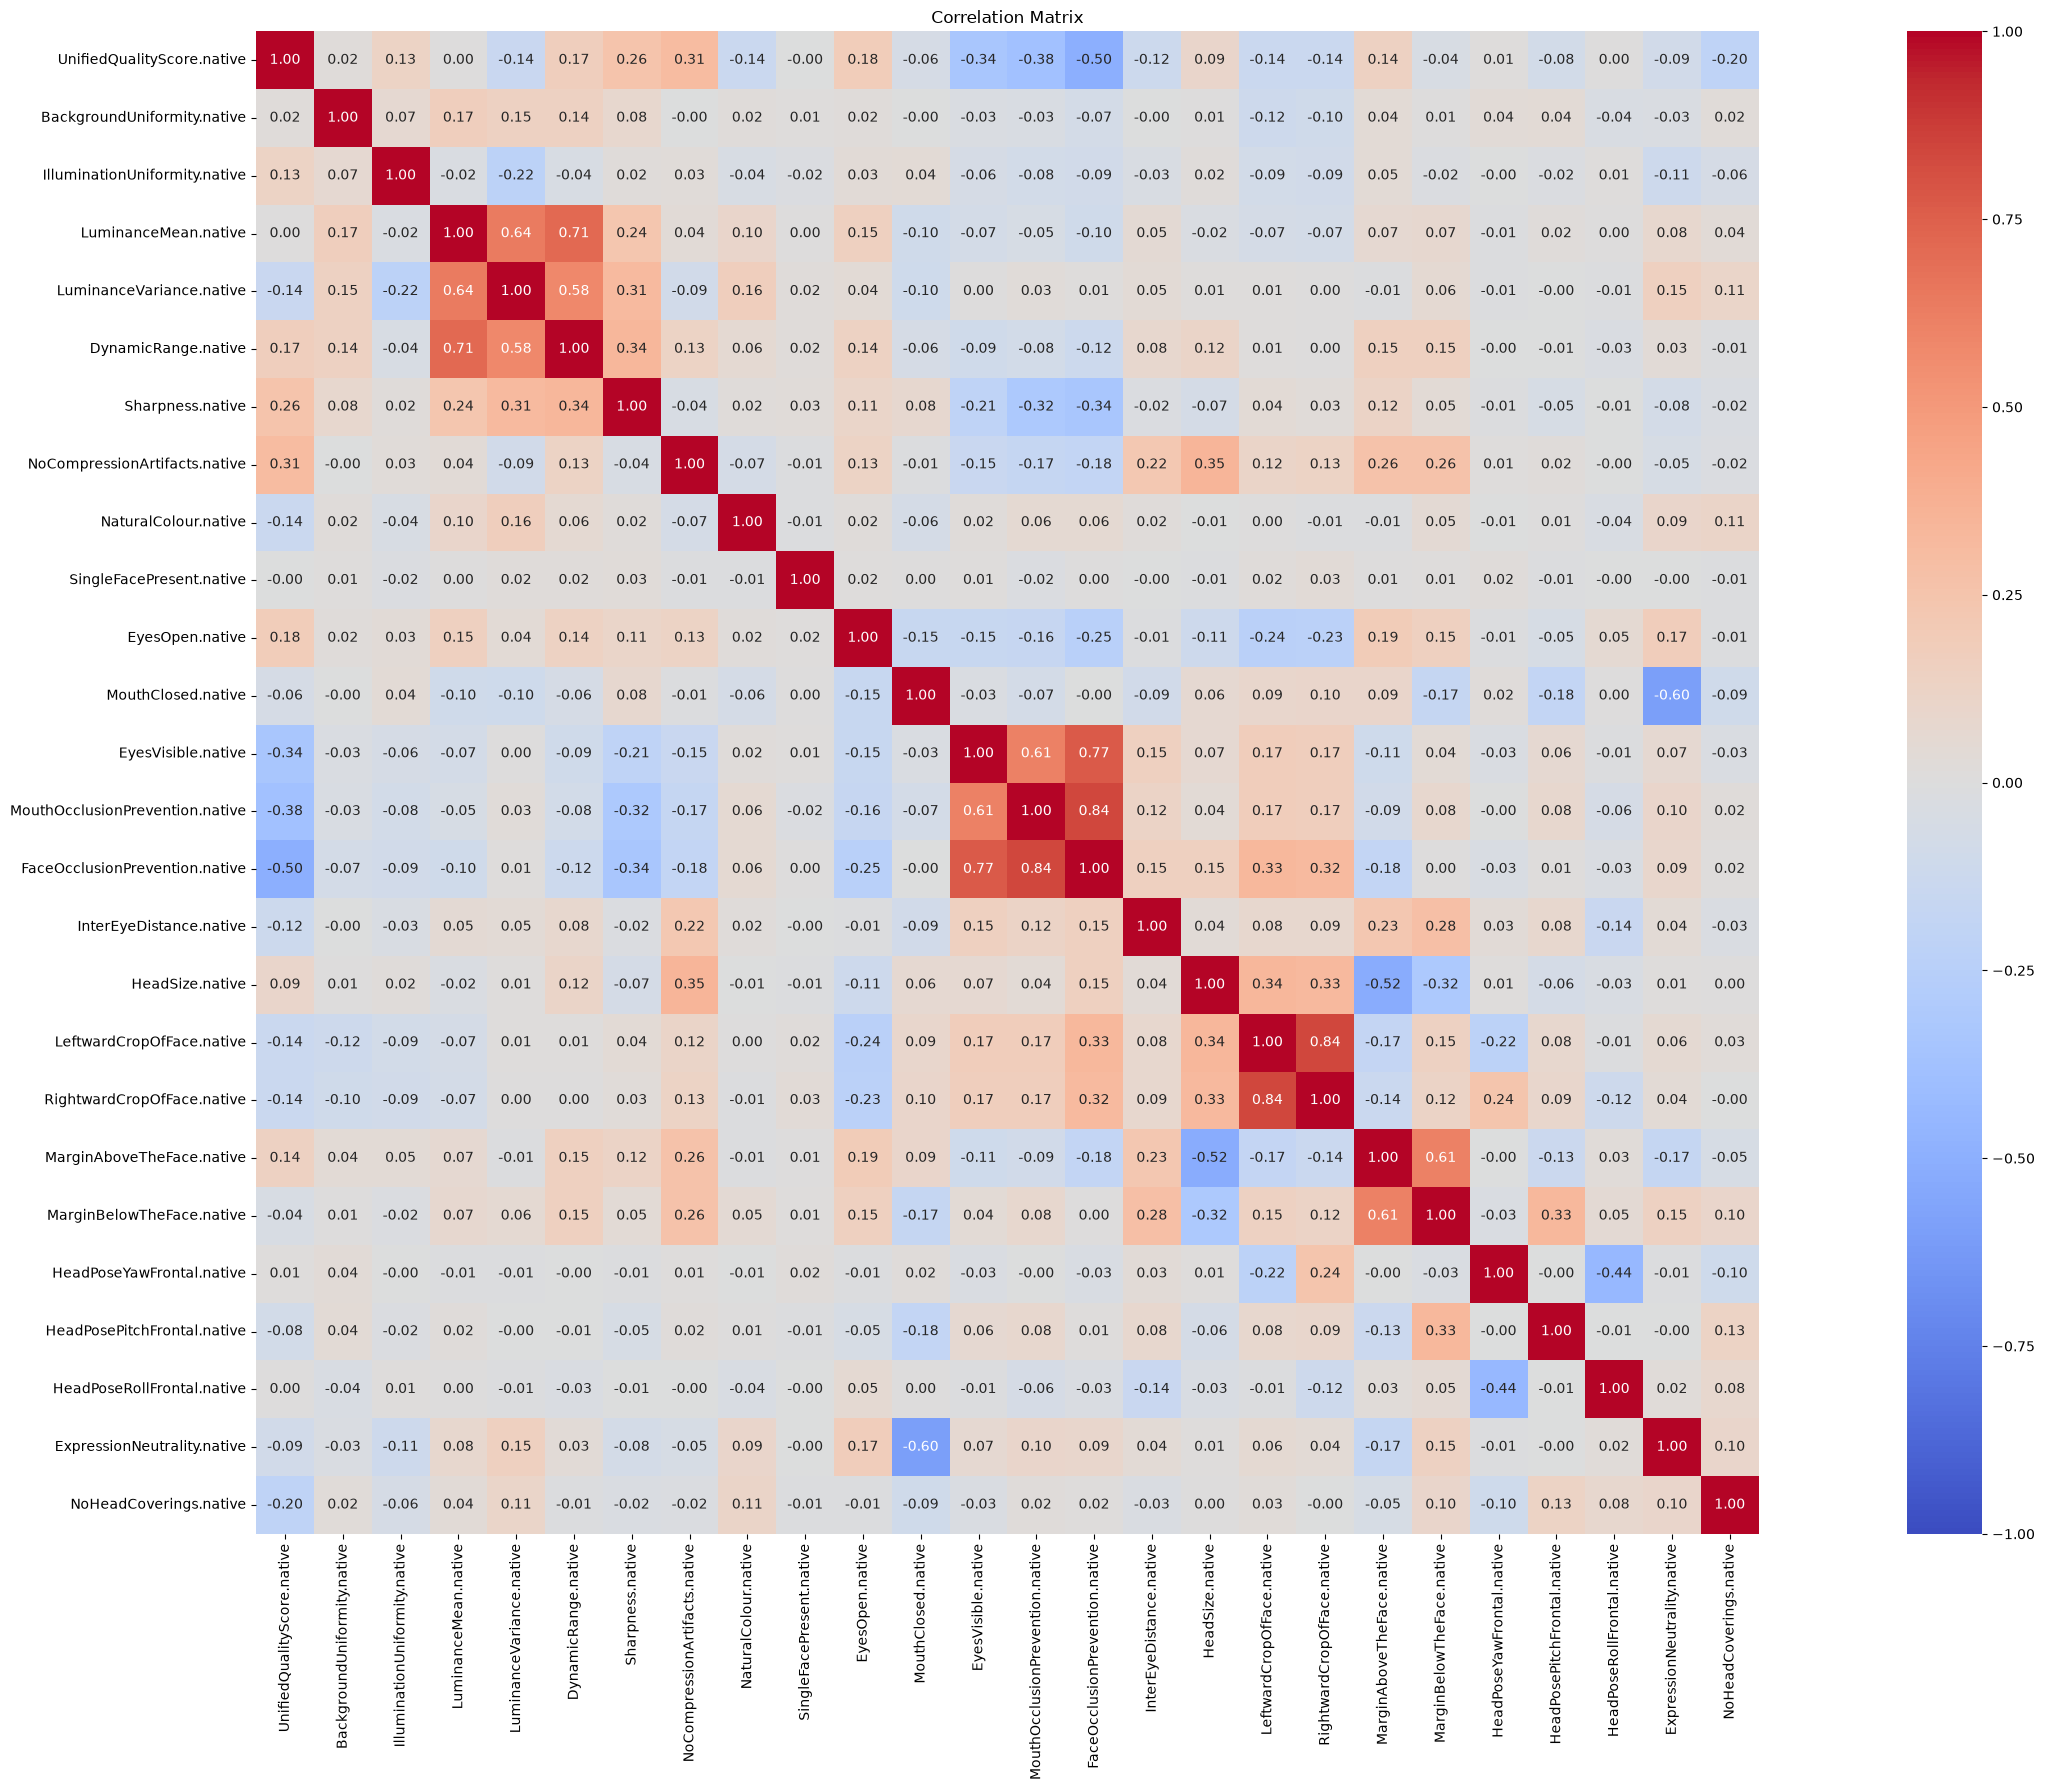

In [35]:
num_df = native.select(cs.numeric())
corr_df = num_df.corr()

corr_pd = corr_df.to_pandas()
corr_pd.index = corr_pd.columns   # le righe prendono i nomi delle colonne

plt.figure(figsize=(30, 18))
sns.heatmap(
    corr_pd,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    square=True,
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()